# 08 · t-tests for means and differences

A t-test compares an estimated mean or mean difference with a hypothesized value, measured in estimated standard errors. The right version depends on the design: one sample, two independent samples, or paired observations.

```mermaid
flowchart TD
    A[Identify independent units] --> B{What comparison?}
    B --> C[One sample against a target]
    B --> D[Two independent groups]
    B --> E[Paired measurements]
    D --> F[Welch or justified pooled variance]
    C --> G[Effect, SE, t, df, interval]
    E --> G
    F --> G
    G --> H[Interpret with assumptions]
```

**Learning route:** t distribution → choose design → calculate → connect to regression → report. Prerequisites: [p-values and intervals](../05_P-Values_for_Confidence_Quantification/05_P-Values_for_Confidence_Quantification.md); the regression connection uses Chapters 6–7.

## 1. Why use a t distribution?

For iid normal observations, if $\sigma$ were known, $(\bar X-\mu)/(\sigma/\sqrt n)$ would be standard normal. Usually $\sigma$ is unknown, so we substitute $S$. That estimated denominator introduces additional uncertainty:

$$T=\frac{\bar X-\mu}{S/\sqrt n}\sim t_{n-1}.$$

A t distribution is symmetric with heavier tails than a standard normal. Its shape depends on degrees of freedom. As degrees of freedom increase, it approaches normal gradually; there is no magic sample size at which they become identical. Heavy tails reflect uncertainty in standardizing the statistic, not a claim that every raw dataset is t distributed.

![Normal and t densities](figure/t_distributions.png)

**Notebook setup.** Run all cells from top to bottom. Figures are saved in this chapter's `figure/` folder. Restart the kernel and run all after changing a simulation. See the repository README for installation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# Works when Jupyter starts in either this chapter or the repository root.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "scripts" / "build_notebooks.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the cloned course repository.")
FIGURE_DIR = ROOT / '08_T-test_for_Testing_the_Differences' / "figure"
FIGURE_DIR.mkdir(exist_ok=True)
plt.rcParams.update({
    "figure.figsize": (9, 4.8), "figure.dpi": 110,
    "font.size": 11, "axes.titlesize": 14, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#087E8B", "#D55E00", "#7251A2", "#4477AA"]),
    "savefig.facecolor": "white", "axes.facecolor": "#FAFBFC",
})
TEAL, ORANGE, PURPLE = "#087E8B", "#D55E00", "#7251A2"

def save_figure(fig, name):
    """Save the exact figure used by Markdown and display it in the notebook."""
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{name}.svg", bbox_inches="tight")
    display(fig)
    plt.close(fig)

print("All datasets in this notebook are synthetic teaching examples.")


All datasets in this notebook are synthetic teaching examples.


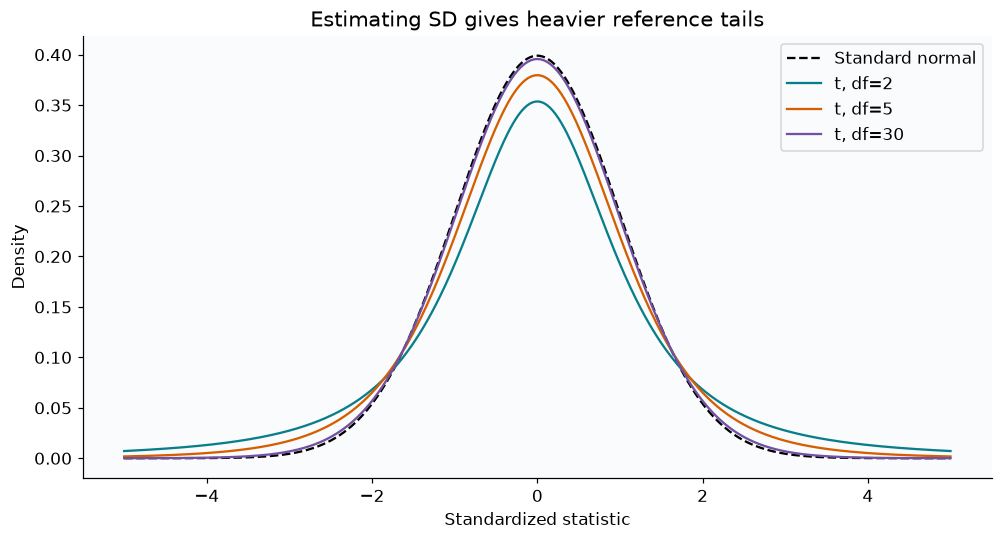

In [2]:
grid = np.linspace(-5,5,600)
fig, ax = plt.subplots(layout="constrained")
ax.plot(grid,stats.norm.pdf(grid),color="black",ls="--",label="Standard normal")
for df in [2,5,30]: ax.plot(grid,stats.t.pdf(grid,df),label=f"t, df={df}")
ax.set(xlabel="Standardized statistic",ylabel="Density",title="Estimating SD gives heavier reference tails")
ax.legend()
save_figure(fig,"t_distributions")

## 2. One-sample t-test

To test $H_0:\mu=\mu_0$, calculate

$$t=\frac{\bar x-\mu_0}{s/\sqrt n},\qquad df=n-1.$$

For a two-sided alternative, $p=2P(t_{df}\ge|t|)$. The corresponding interval is $\bar x\pm t_{1-\alpha/2,df}s/\sqrt n$. A one-sided test uses the appropriate tail chosen beforehand.

For invented filling volumes 48, 49, 50, 51, 52 mL, the mean is 50 and sample variance is 2.5. Testing a target of 49 mL gives $t=(50-49)/\sqrt{2.5/5}=\sqrt2$, with four degrees of freedom. The notebook computes its p-value and interval. The mean differs descriptively from the target; whether it is well distinguished from the target depends on uncertainty.

In [3]:
volumes = np.array([48,49,50,51,52],dtype=float)
one = stats.ttest_1samp(volumes,49)
assert np.isclose(one.statistic,np.sqrt(2))
print("One-sample test:",one)
print("95% interval for the mean:",one.confidence_interval())

One-sample test: TtestResult(statistic=np.float64(1.414213562373095), pvalue=np.float64(0.2301996410804989), df=np.int64(4))
95% interval for the mean: ConfidenceInterval(low=np.float64(48.03675683852244), high=np.float64(51.96324316147756))


## 3. Independent groups: Welch's t-test

For independent samples A and B, define $\Delta=\mu_B-\mu_A$. With possibly different population variances, the estimated standard error is

$$SE=\sqrt{\frac{s_B^2}{n_B}+\frac{s_A^2}{n_A}},\qquad
t=\frac{(\bar x_B-\bar x_A)-\Delta_0}{SE}.$$

Welch's approximate degrees of freedom are

$$\nu=\frac{(s_B^2/n_B+s_A^2/n_A)^2}
{(s_B^2/n_B)^2/(n_B-1)+(s_A^2/n_A)^2/(n_A-1)}.$$

Fractional degrees of freedom are normal here. The Welch–Satterthwaite approximation accounts for uncertainty from estimating two variances. Welch's method does not require equal variances and is a sensible starting choice for two independent means when equal variance is not justified. It still requires appropriate independent sampling and is not immune to severe skewness or influential observations in small samples.

### Worked example: two preparation processes

Use independent invented times, in minutes:

| Process | Times | $n$ | Mean | Sample variance |
|---|---|---:|---:|---:|
| A | 15, 17, 18, 19, 21 | 5 | 18 | 5 |
| B | 12, 13, 14, 16, 20, 21 | 6 | 16 | 14 |

For $H_0:\Delta=0$, the effect estimate is $16-18=-2$ minutes. The SE is $\sqrt{14/6+5/5}=\sqrt{10/3}\approx1.826$, and $t\approx-1.095$. Welch degrees of freedom are approximately 8.299. The two-sided p-value is about 0.30; the interval includes zero and potentially meaningful effects in either direction. This is insufficient precision to claim equality or an established improvement.

![Independent process times and an interval for the mean difference](figure/welch_comparison.png)

B-A=-2.000, SE=1.8257, df=8.2988, t=-1.0954, p=0.3041
95% Welch CI: [-6.1839315  2.1839315]


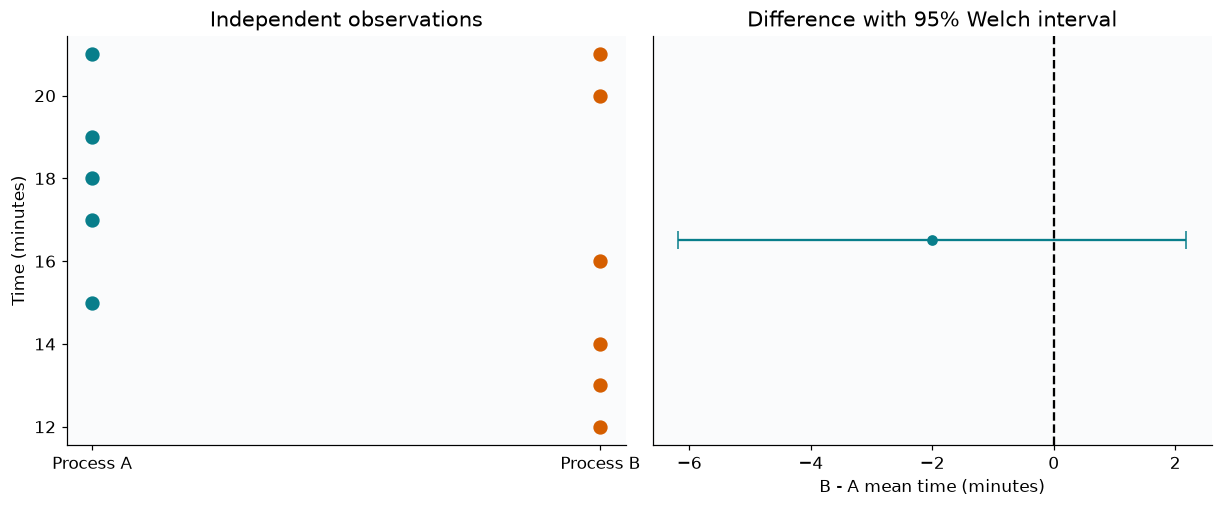

In [4]:
a = np.array([15,17,18,19,21],dtype=float)
b = np.array([12,13,14,16,20,21],dtype=float)
delta = b.mean()-a.mean()
va,vb = a.var(ddof=1)/len(a),b.var(ddof=1)/len(b)
se = np.sqrt(va+vb)
df_w = (va+vb)**2/(va**2/(len(a)-1)+vb**2/(len(b)-1))
t_w = delta/se
welch = stats.ttest_ind(b,a,equal_var=False)
ci = delta+np.array([-1,1])*stats.t.ppf(.975,df_w)*se
assert np.isclose(welch.statistic,t_w) and np.isclose(welch.df,df_w)
assert np.allclose(ci,welch.confidence_interval())
print(f"B-A={delta:.3f}, SE={se:.4f}, df={df_w:.4f}, t={t_w:.4f}, p={welch.pvalue:.4f}")
print("95% Welch CI:",ci)
fig, axes = plt.subplots(1,2,figsize=(11,4.5),layout="constrained")
axes[0].scatter(np.zeros(len(a)),a,s=70,label="A")
axes[0].scatter(np.ones(len(b)),b,s=70,label="B")
axes[0].set(xticks=[0,1],xticklabels=["Process A","Process B"],ylabel="Time (minutes)",title="Independent observations")
axes[1].errorbar(delta,0,xerr=[[delta-ci[0]],[ci[1]-delta]],fmt="o",capsize=6,color=TEAL)
axes[1].axvline(0,color="black",ls="--")
axes[1].set(xlabel="B - A mean time (minutes)",yticks=[],ylim=(-1,1),title="Difference with 95% Welch interval")
save_figure(fig,"welch_comparison")

Report the effect and interval even when the p-value is large. Reporting only “not significant” discards useful information about magnitude and precision.

## 4. Equal-variance Student test and its regression connection

If a common population variance is justified, pool the within-group information:

$$s_p^2=\frac{(n_A-1)s_A^2+(n_B-1)s_B^2}{n_A+n_B-2},$$

$$t=\frac{(\bar x_B-\bar x_A)-\Delta_0}
{s_p\sqrt{1/n_A+1/n_B}},\qquad df=n_A+n_B-2.$$

For our example, $s_p^2=10$. This is a weighted average of variances, not an unweighted average of SDs. Equal sample sizes do not establish equal population variances. Choosing between pooled and Welch tests solely by first testing variance equality can make the overall procedure harder to interpret; state the variance model directly.

Regress all observations on an intercept and indicator $z=1$ for B, $z=0$ for A. The intercept estimates A's mean and the indicator coefficient estimates B minus A. Under ordinary homoscedastic OLS, the indicator's t-test equals the **pooled** two-sample t-test, and the one-degree-of-freedom F-test equals $t^2$.

This equivalence does not generally turn the ordinary OLS F-test into Welch's test. Welch uses a different variance estimate and degrees-of-freedom approximation. In both cases, the direction of a contrast is lost when squaring its t statistic; retain the signed effect in the report.

In [5]:
import statsmodels.api as sm
all_y = np.r_[a,b]
indicator = np.r_[np.zeros(len(a)),np.ones(len(b))]
regression = sm.OLS(all_y,sm.add_constant(indicator)).fit()
pooled = stats.ttest_ind(b,a,equal_var=True)
assert np.isclose(pooled.statistic,regression.tvalues[1])
assert np.isclose(pooled.pvalue,regression.f_pvalue)
assert np.isclose(regression.fvalue,pooled.statistic**2)
print("Pooled t p-value:",pooled.pvalue,"OLS F p-value:",regression.f_pvalue)
print("Welch p-value differs because it uses another variance model:",welch.pvalue)

Pooled t p-value: 0.32351092916629454 OLS F p-value: 0.32351092916629504
Welch p-value differs because it uses another variance model: 0.30409220264762493


## 5. Paired observations: analyze differences within pairs

When the same device is measured before and after a setting change, the measurements are paired. Let $d_i=\text{after}_i-\text{before}_i$. Test the mean difference with a one-sample t-test:

$$t=\frac{\bar d-\Delta_0}{s_d/\sqrt n},\qquad df=n-1,$$

where $n$ is the number of independent pairs. The relevant normality assumption for an exact small-sample test concerns the **differences**, not the separate before and after distributions.

Consider before times $(40,50,60,70,80)$ and after times $(38,47,59,66,78)$ seconds for five devices. Differences are $(-2,-3,-1,-4,-2)$, with mean $-2.4$ and sample variance 1.3. Their SE is $\sqrt{1.3/5}\approx0.510$, much smaller than the spread of the raw device times.

![Paired observations preserve the within-device comparison](figure/paired_times.png)

Paired mean difference: -2.4 sample variance: 1.3
Paired test: TtestResult(statistic=np.float64(-4.706787243316416), pvalue=np.float64(0.009261696759514423), df=np.int64(4)) 95% CI: ConfidenceInterval(low=np.float64(-3.815714776982272), high=np.float64(-0.9842852230177277))


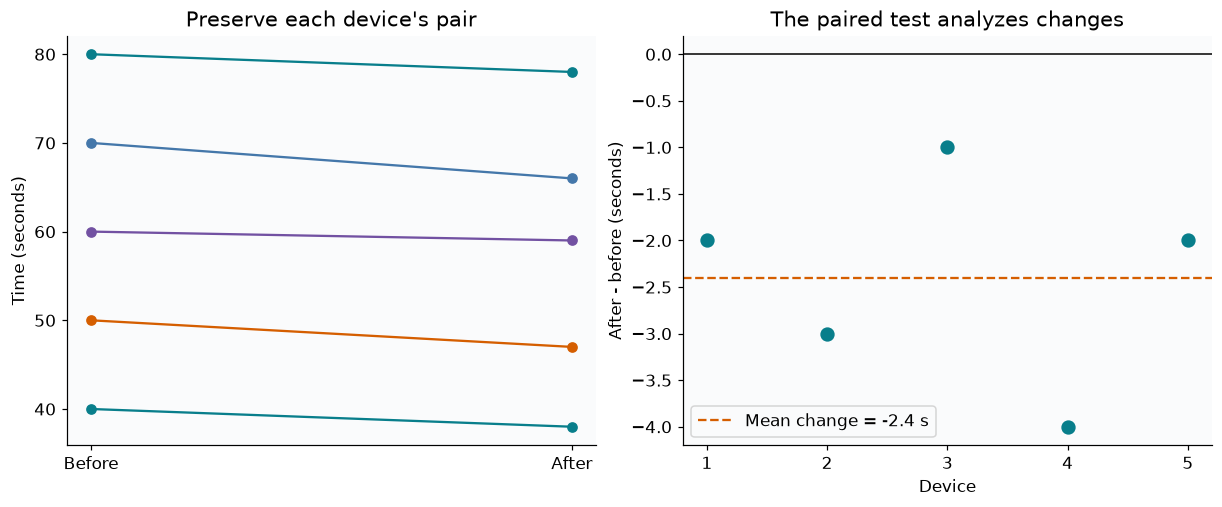

In [6]:
before = np.array([40,50,60,70,80],dtype=float)
after = np.array([38,47,59,66,78],dtype=float)
d = after-before
paired = stats.ttest_rel(after,before)
assert np.isclose(paired.statistic,stats.ttest_1samp(d,0).statistic)
print("Paired mean difference:",d.mean(),"sample variance:",d.var(ddof=1))
print("Paired test:",paired,"95% CI:",paired.confidence_interval())
fig, axes = plt.subplots(1,2,figsize=(11,4.5),layout="constrained")
for i,(v_before,v_after) in enumerate(zip(before,after)):
    axes[0].plot([0,1],[v_before,v_after],"o-",label=f"Device {i+1}")
axes[0].set(xticks=[0,1],xticklabels=["Before","After"],ylabel="Time (seconds)",title="Preserve each device's pair")
axes[1].scatter(np.arange(1,6),d,s=70,color=TEAL)
axes[1].axhline(d.mean(),color=ORANGE,ls="--",label="Mean change = -2.4 s")
axes[1].axhline(0,color="black",lw=1)
axes[1].set(xlabel="Device",ylabel="After - before (seconds)",xticks=np.arange(1,6),title="The paired test analyzes changes")
axes[1].legend()
save_figure(fig,"paired_times")

Pairing works because $\operatorname{Var}(A-B)=\operatorname{Var}(A)+\operatorname{Var}(B)-2\operatorname{Cov}(A,B)$. Positive within-pair association can reduce difference variability. Arbitrary pairing after seeing the data is not a valid way to obtain this advantage. Pairing must come from the design, and missing one measurement can remove an entire pair from a complete-pair analysis.

## 6. Assumptions, alternatives, and effect sizes

Independence cannot be established by a normality test. Repeated observations, matched observations, and cluster assignments require their respective designs to be represented in the analysis. Large independent samples can make mean-based inference approximately valid under suitable moment conditions, but severe heavy tails or influential points can still matter.

If assumptions are implausible, consider a justified transformation, robust estimation, a design-respecting randomization test, or a suitable distributional model. Rank tests are not automatic replacements for tests of mean differences: their hypotheses and interpretation differ.

An unstandardized mean difference keeps the measurement units. Cohen's $d$ divides a difference by a specified SD, often the pooled SD for independent groups. For paired designs, different standardized effect definitions use different denominators; name the convention. Hedges' correction can reduce small-sample bias in standardized effects. None of these replaces an interval or a meaningful practical threshold.

## 7. Practice

1. Six independent pairs have differences 1, 2, 2, 3, 3, 1. Find the mean difference, its SE, t for zero difference, and degrees of freedom.
2. An unpaired study has $n_A=10,n_B=20,s_A^2=9,s_B^2=16$. Find the Welch SE. Can you use $df=28$ automatically?
3. A student passes paired before and after data to `ttest_ind`. Why might the result be inefficient or inappropriate?
4. When does $F=t^2$ give the same two-sided inference for a group difference?
5. Why should a mean difference and interval be reported even if $p>0.05$?

## 8. Worked answers

1. $\bar d=2$, squared deviations sum to 4, so $s_d^2=4/5=0.8$, $SE=\sqrt{0.8/6}\approx0.3651$, $t=\sqrt{30}\approx5.477$, and $df=5$.
2. $SE=\sqrt{9/10+16/20}=\sqrt{1.7}\approx1.3038$. No: Welch uses its approximate df formula, here about 23.37.
3. The independent-sample formula discards the paired covariance and does not represent the actual sampling structure. Use differences or an appropriate paired model.
4. For the same one-degree-of-freedom contrast and variance model, such as a pooled two-sample t-test and ordinary two-group homoscedastic regression.
5. They show which effect magnitudes remain plausible under the model; a threshold label alone does not.

In [7]:
differences = np.array([1,2,2,3,3,1],dtype=float)
assert np.isclose(stats.ttest_1samp(differences,0).statistic,np.sqrt(30))
nu = (9/10+16/20)**2/((9/10)**2/9+(16/20)**2/19)
print("Practice 1:",stats.ttest_1samp(differences,0))
print("Practice 2 Welch SE:",np.sqrt(1.7),"df:",nu)

Practice 1: TtestResult(statistic=np.float64(5.477225575051661), pvalue=np.float64(0.0027649603013049557), df=np.int64(5))
Practice 2 Welch SE: 1.3038404810405297 df: 23.365957446808512


## References and next step

Reading connection: Starmer (2026), Chapter 8, [SQ](../Reference.md#sq-statquest). Welch and paired extensions: [NIST two-sample t-test](https://www.itl.nist.gov/div898/handbook/eda/section3/eda353.htm). API choices: [SciPy ttest_ind](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html) and [ttest_rel](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_rel.html).

Next: [09 · Power and sample size](../09_Power_and_Power_Analysis/09_Power_and_Power_Analysis.md).